# Day 05: CelebA Face Attributes – CNN vs CLIP
Goal: build a multi-label CNN to detect 3 face attributes at the same time, then compare it with CLIP used zero-shot (no training) using F1-score.

In [4]:
import kagglehub, os

# Download CelebA (about 1.4 GB, takes 2–4 minutes)
path = kagglehub.dataset_download("jessicali9530/celeba-dataset")
print("Downloaded to:", path)

# Show what's inside (folders and files at the top levels)
for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)
    if depth <= 2:
        imgs = [f for f in files if f.endswith(".jpg")]
        csvs = [f for f in files if f.endswith(".csv")]
        print("  " * depth + os.path.basename(root) + "/",
              f"({len(imgs)} jpg, csv: {csvs})" if (imgs or csvs) else "")

Using Colab cache for faster access to the 'celeba-dataset' dataset.
Downloaded to: /kaggle/input/celeba-dataset
celeba-dataset/ (0 jpg, csv: ['list_landmarks_align_celeba.csv', 'list_eval_partition.csv', 'list_attr_celeba.csv', 'list_bbox_celeba.csv'])
  img_align_celeba/ 
    img_align_celeba/ (202599 jpg, csv: [])


In [5]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Find the answer sheet (CSV) and the photo folder
attr_csv = glob.glob(f"{path}/**/list_attr_celeba.csv", recursive=True)[0]
img_dir = os.path.dirname(glob.glob(f"{path}/**/000001.jpg", recursive=True)[0])
print("Attributes file:", attr_csv)
print("Photo folder:", img_dir)

# 2. Read the 40 attributes
attrs = pd.read_csv(attr_csv)
print("\nAll 40 attributes:", list(attrs.columns[1:]))

# 3. Pick our 3 attributes (CelebA uses -1 = no, 1 = yes → change to 0 / 1)
df = pd.DataFrame({
    "image_id":   attrs["image_id"],
    "Smiling":    (attrs["Smiling"] == 1).astype(int),
    "Eyeglasses": (attrs["Eyeglasses"] == 1).astype(int),
    "Beard":      (attrs["No_Beard"] == -1).astype(int),   # "No_Beard = no" means HAS a beard
})

# 4. Use a random 20,000 photos (the task asks for ~20,000)
df = df.sample(n=20000, random_state=42).reset_index(drop=True)
LABELS = ["Smiling", "Eyeglasses", "Beard"]

print("\nPhotos used:", len(df))
print("\nHow many have each attribute:")
print((df[LABELS].mean() * 100).round(1).astype(str) + " %")

Attributes file: /kaggle/input/celeba-dataset/list_attr_celeba.csv
Photo folder: /kaggle/input/celeba-dataset/img_align_celeba/img_align_celeba

All 40 attributes: ['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young']

Photos used: 20000

How many have each attribute:
Smiling       48.4 %
Eyeglasses     6.3 %
Beard         16.5 %
dtype: object


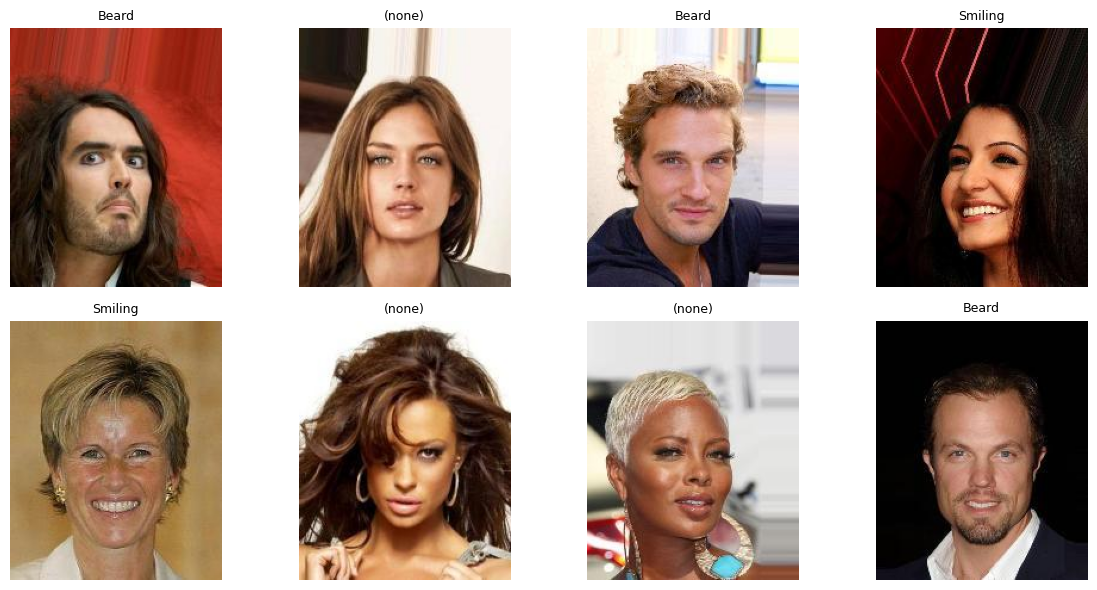

In [6]:
from PIL import Image

plt.figure(figsize=(12, 6))
for i in range(8):
    row = df.iloc[i]
    img = Image.open(os.path.join(img_dir, row["image_id"]))
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    tags = [l for l in LABELS if row[l] == 1]
    plt.title(", ".join(tags) if tags else "(none)", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

# 1. Split the 20,000 photos: 80% train, 10% validation, 10% test
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.5, random_state=42)
print(f"Train: {len(train_df)}  |  Validation: {len(val_df)}  |  Test: {len(test_df)}")

IMG_SIZE = 128   # resize faces to 128 x 128 (smaller = faster)
BATCH = 64

# 2. A small function that opens one photo and prepares it
def load_image(file_name, labels):
    img = tf.io.read_file(img_dir + "/" + file_name)   # read the file
    img = tf.image.decode_jpeg(img, channels=3)          # turn it into pixels (colour)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))     # resize to 128 x 128
    img = img / 255.0                                     # pixels 0–255 → 0–1
    return img, labels

# 3. Turn each table into a stream of (photo, 3 labels)
def make_dataset(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["image_id"].values, frame[LABELS].values.astype("float32")))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=42)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

# Quick check: one batch
imgs, labs = next(iter(train_ds))
print("Photo batch shape:", imgs.shape)    # (64, 128, 128, 3)
print("Label batch shape:", labs.shape)    # (64, 3) ← 3 answers per photo!
print("First photo's labels:", labs[0].numpy(), "→", LABELS)

Train: 16000  |  Validation: 2000  |  Test: 2000
Photo batch shape: (64, 128, 128, 3)
Label batch shape: (64, 3)
First photo's labels: [0. 0. 0.] → ['Smiling', 'Eyeglasses', 'Beard']


## Preparing the data
- Split: 16,000 train / 2,000 validation / 2,000 test. The same test set is used for both the CNN and CLIP, so the comparison is fair.
- Photos resized to 128 x 128 and scaled to 0–1.
- Each photo has 3 labels (0 or 1), one per attribute.

In [8]:
cnn = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),         # a 128 x 128 colour face

    layers.RandomFlip("horizontal"),                     # mirror faces sometimes (a smile is still a smile!)

    layers.Conv2D(32, 3, activation="relu", padding="same"),   # 🔍 find edges and lines
    layers.MaxPooling2D(),                                     # 📏 shrink
    layers.Conv2D(64, 3, activation="relu", padding="same"),   # 🔍 find shapes (mouth, eyes)
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"),  # 🔍 find bigger parts (glasses frame, beard)
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),                     # 📋 summarise the clues
    layers.Dropout(0.3),                                 # 😴 switch off 30% to avoid memorising
    layers.Dense(64, activation="relu"),                 # 🧠 think
    layers.Dense(3, activation="sigmoid")                # ✅❌ 3 separate yes/no answers!
])

cnn.compile(optimizer="adam",
            loss="binary_crossentropy",                  # ← multi-label loss
            metrics=[keras.metrics.BinaryAccuracy(name="acc"),
                     keras.metrics.AUC(name="auc", multi_label=True)])
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

## Model 1: Multi-label CNN
- 3 convolution blocks (32 → 64 → 128 filters) + global average pooling, dropout and dense layers.
- Output: Dense(3, sigmoid), three independent yes/no predictions, because one face can have several attributes at once (softmax would force only one).
- Loss: binary cross-entropy (each attribute is its own yes/no question).

In [9]:
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [10]:
IMG_SIZE = 96   # a bit smaller = faster (faces are still clear)

def load_image(file_name, labels):
    img = tf.io.read_file(img_dir + "/" + file_name)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.uint8)          # store small (0–255 whole numbers) to save memory
    return img, labels

def scale(img, labels):
    return tf.cast(img, tf.float32) / 255.0, labels   # 0–255 → 0–1

def make_dataset(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["image_id"].values, frame[LABELS].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.cache()                       # ⭐ remember the photos after the first read!
    if shuffle:
        ds = ds.shuffle(len(frame), seed=42)
    return ds.map(scale).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)
print("Datasets ready ✅")

Datasets ready ✅


In [4]:
# ==================== Day 05: CelebA – CNN vs CLIP (all in one) ====================
import os, glob, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score
import kagglehub

# Let TensorFlow and PyTorch (CLIP) share the GPU
try:
    for g in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(g, True)
except RuntimeError:
    pass
print("GPU:", tf.config.list_physical_devices("GPU"))

# ---------- 1. Data ----------
path = kagglehub.dataset_download("jessicali9530/celeba-dataset")
attr_csv = glob.glob(f"{path}/**/list_attr_celeba.csv", recursive=True)[0]
img_dir = os.path.dirname(glob.glob(f"{path}/**/000001.jpg", recursive=True)[0])

attrs = pd.read_csv(attr_csv)
df = pd.DataFrame({
    "image_id":   attrs["image_id"],
    "Smiling":    (attrs["Smiling"] == 1).astype(int),
    "Eyeglasses": (attrs["Eyeglasses"] == 1).astype(int),
    "Beard":      (attrs["No_Beard"] == -1).astype(int),   # No_Beard = -1 → has a beard
})
df = df.sample(n=20000, random_state=42).reset_index(drop=True)
LABELS = ["Smiling", "Eyeglasses", "Beard"]
print("\n% of photos with each attribute:")
print((df[LABELS].mean() * 100).round(1))

# ---------- 2. Split + fast datasets ----------
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)
val_df, test_df   = train_test_split(temp_df, test_size=0.5, random_state=42)
IMG_SIZE, BATCH = 96, 64

def load_image(file_name, labels):
    img = tf.io.read_file(img_dir + "/" + file_name)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.uint8), labels

def scale(img, labels):
    return tf.cast(img, tf.float32) / 255.0, labels

def make_dataset(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (frame["image_id"].values, frame[LABELS].values.astype("float32")))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(frame), seed=42)
    return ds.map(scale).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, shuffle=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)
print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# ---------- 3. Multi-label CNN ----------
cnn = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.Conv2D(32, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation="relu", padding="same"), layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(3, activation="sigmoid"),          # 3 independent yes/no answers
])
cnn.compile(optimizer="adam", loss="binary_crossentropy",
            metrics=[keras.metrics.BinaryAccuracy(name="acc"),
                     keras.metrics.AUC(name="auc", multi_label=True)])

early_stop = keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                           patience=3, restore_best_weights=True)
start = time.time()
history = cnn.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[early_stop], verbose=2)
print(f"CNN training time: {(time.time() - start)/60:.1f} min")

# ---------- 4. CNN predictions (threshold tuned on validation, applied to test) ----------
y_val, y_test = val_df[LABELS].values, test_df[LABELS].values
p_val  = cnn.predict(val_ds, verbose=0)
p_test = cnn.predict(test_ds, verbose=0)

thresholds = []
for j in range(3):
    ts = np.arange(0.10, 0.91, 0.05)
    f1s = [f1_score(y_val[:, j], (p_val[:, j] >= t).astype(int), zero_division=0) for t in ts]
    thresholds.append(ts[int(np.argmax(f1s))])
cnn_pred = (p_test >= np.array(thresholds)).astype(int)
print("CNN thresholds (from validation):", dict(zip(LABELS, np.round(thresholds, 2))))

# ---------- 5. CLIP zero-shot (no training!) ----------
import torch
from transformers import CLIPModel, CLIPProcessor
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

PROMPTS = {   # [YES sentence, NO sentence] for each attribute
    "Smiling":    ["a photo of a smiling person", "a photo of a person with a neutral face, not smiling"],
    "Eyeglasses": ["a photo of a person wearing eyeglasses", "a photo of a person not wearing eyeglasses"],
    "Beard":      ["a photo of a man with a beard", "a photo of a person with a clean-shaven face"],
}
texts = [p for l in LABELS for p in PROMPTS[l]]

with torch.no_grad():
    t_in = proc(text=texts, return_tensors="pt", padding=True).to(device)
    t_emb = clip.get_text_features(**t_in)
    t_emb = t_emb / t_emb.norm(dim=-1, keepdim=True)

start = time.time()
clip_probs = []
files = test_df["image_id"].values
for i in range(0, len(files), 64):
    imgs = [Image.open(os.path.join(img_dir, f)).convert("RGB") for f in files[i:i + 64]]
    with torch.no_grad():
        i_in = proc(images=imgs, return_tensors="pt").to(device)
        i_emb = clip.get_image_features(**i_in)
        i_emb = i_emb / i_emb.norm(dim=-1, keepdim=True)
        logits = (100 * i_emb @ t_emb.T).view(-1, 3, 2)     # (photos, 3 attributes, YES/NO)
        probs = logits.softmax(dim=-1)[:, :, 0]              # chance of the YES sentence
    clip_probs.append(probs.cpu().numpy())
clip_probs = np.concatenate(clip_probs)
clip_pred = (clip_probs >= 0.5).astype(int)
print(f"CLIP time on {len(files)} test photos: {time.time() - start:.0f} s")

# ---------- 6. Compare: F1, precision, recall ----------
rows = []
for name, pred in [("CNN (trained)", cnn_pred), ("CLIP (zero-shot)", clip_pred)]:
    for j, lab in enumerate(LABELS):
        rows.append({"Model": name, "Attribute": lab,
                     "Precision": precision_score(y_test[:, j], pred[:, j], zero_division=0),
                     "Recall":    recall_score(y_test[:, j], pred[:, j], zero_division=0),
                     "F1":        f1_score(y_test[:, j], pred[:, j], zero_division=0)})
results = pd.DataFrame(rows).round(3)
print("\n================ RESULTS (2,000 test photos) ================")
print(results.to_string(index=False))
print("\nMacro F1 (average of 3 attributes):")
print(results.groupby("Model")["F1"].mean().round(3))

# Chart: F1 per attribute
pivot = results.pivot(index="Attribute", columns="Model", values="F1").loc[LABELS]
ax = pivot.plot(kind="bar", figsize=(8, 4), color=["tab:blue", "tab:orange"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.title("F1-score per attribute: CNN (trained) vs CLIP (zero-shot)")
plt.ylabel("F1-score"); plt.ylim(0, 1.05); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

# Example faces
plt.figure(figsize=(14, 7))
for k in range(8):
    r = test_df.iloc[k]
    plt.subplot(2, 4, k + 1)
    plt.imshow(Image.open(os.path.join(img_dir, r["image_id"])))
    true = [l[:5] for j, l in enumerate(LABELS) if y_test[k, j]]
    c_   = [l[:5] for j, l in enumerate(LABELS) if cnn_pred[k, j]]
    cl_  = [l[:5] for j, l in enumerate(LABELS) if clip_pred[k, j]]
    plt.title(f"True: {', '.join(true) or '-'}\nCNN: {', '.join(c_) or '-'}\nCLIP: {', '.join(cl_) or '-'}", fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

# ---------- 7. Save ----------
cnn.save("celeba_cnn.keras")
results.to_csv("day05_results.csv", index=False)
print("\nSaved: celeba_cnn.keras, day05_results.csv ✅  Day 5 done! 🎉")

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using Colab cache for faster access to the 'celeba-dataset' dataset.

% of photos with each attribute:
Smiling       48.4
Eyeglasses     6.3
Beard         16.5
dtype: float64

Train: 16000 | Val: 2000 | Test: 2000
Epoch 1/15
250/250 - 78s - 314ms/step - acc: 0.7626 - auc: 0.5403 - loss: 0.4661 - val_acc: 0.7717 - val_auc: 0.5677 - val_loss: 0.4515
Epoch 2/15
250/250 - 5s - 22ms/step - acc: 0.7680 - auc: 0.5671 - loss: 0.4582 - val_acc: 0.7768 - val_auc: 0.6106 - val_loss: 0.4436
Epoch 3/15
250/250 - 5s - 21ms/step - acc: 0.7748 - auc: 0.6087 - loss: 0.4503 - val_acc: 0.7795 - val_auc: 0.6694 - val_loss: 0.4330
Epoch 4/15
250/250 - 10s - 41ms/step - acc: 0.7842 - auc: 0.6599 - loss: 0.4392 - val_acc: 0.7940 - val_auc: 0.6903 - val_loss: 0.4251
Epoch 5/15
250/250 - 5s - 21ms/step - acc: 0.7885 - auc: 0.6881 - loss: 0.4308 - val_acc: 0.8052 - val_auc: 0.7130 - val_loss: 0.4190
Epoch 6/15
250/250 - 5s - 21ms/step - acc

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP time on 2000 test photos: 20 s

================ RESULTS (2,000 test photos) ================
           Model  Attribute  Precision  Recall    F1
   CNN (trained)    Smiling      0.862   0.837 0.850
   CNN (trained) Eyeglasses      0.806   0.500 0.617
   CNN (trained)      Beard      0.504   0.763 0.607
CLIP (zero-shot)    Smiling      0.929   0.425 0.583
CLIP (zero-shot) Eyeglasses      0.786   0.407 0.537
CLIP (zero-shot)      Beard      0.896   0.178 0.297

Macro F1 (average of 3 attributes):
Model
CLIP (zero-shot)    0.472
CNN (trained)       0.691
Name: F1, dtype: float64


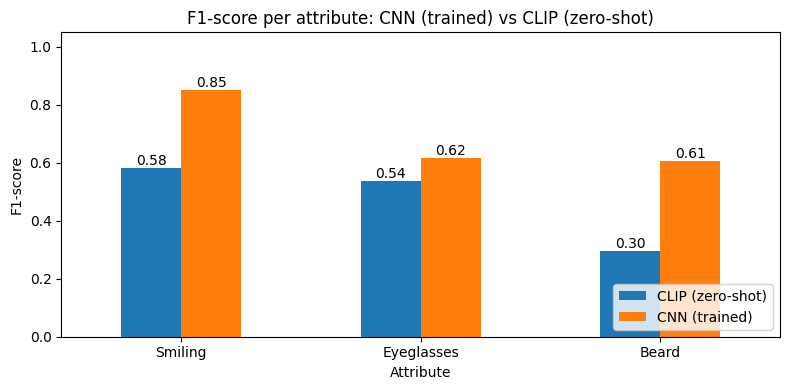

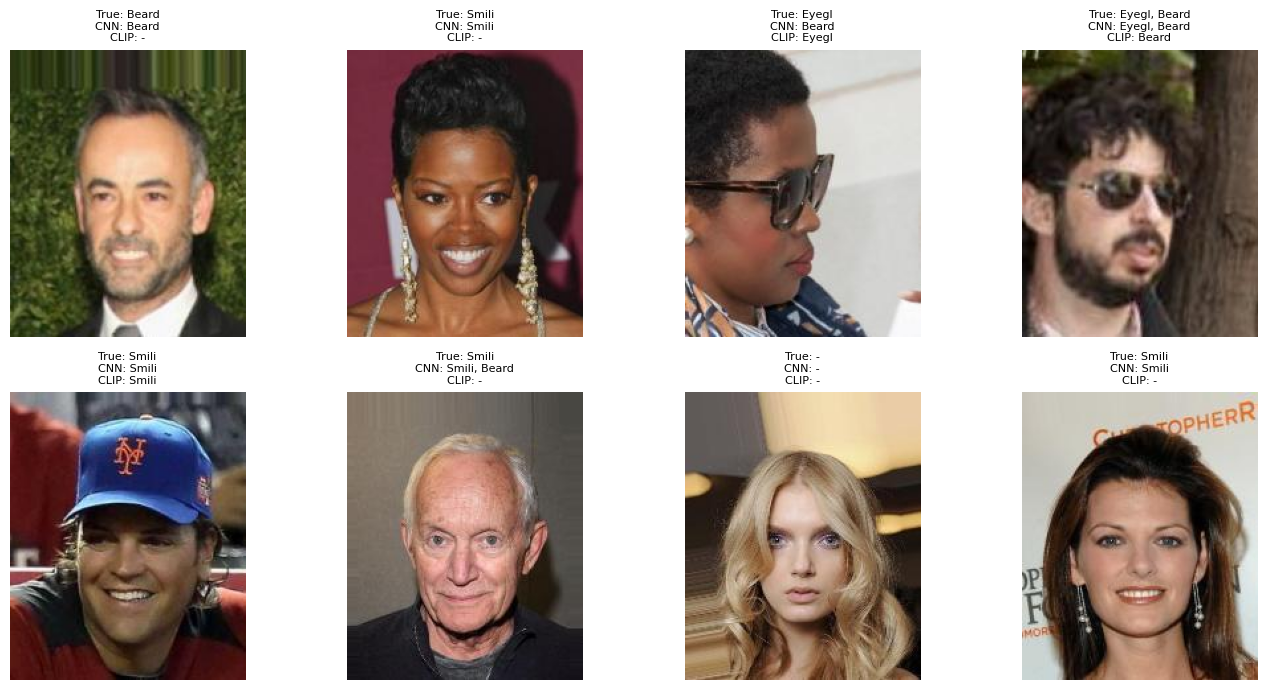


Saved: celeba_cnn.keras, day05_results.csv ✅  Day 5 done! 🎉


In [5]:
# ---------- 5. CLIP zero-shot (no training!) ----------
import torch
from transformers import CLIPModel, CLIPProcessor
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Version-safe helpers: get text / image embeddings directly from CLIP's parts
def text_embed(inputs):
    out = clip.text_model(input_ids=inputs["input_ids"], attention_mask=inputs["attention_mask"])
    emb = clip.text_projection(out.pooler_output)
    return emb / emb.norm(dim=-1, keepdim=True)

def image_embed(pixel_values):
    out = clip.vision_model(pixel_values=pixel_values)
    emb = clip.visual_projection(out.pooler_output)
    return emb / emb.norm(dim=-1, keepdim=True)

PROMPTS = {   # [YES sentence, NO sentence] for each attribute
    "Smiling":    ["a photo of a smiling person", "a photo of a person with a neutral face, not smiling"],
    "Eyeglasses": ["a photo of a person wearing eyeglasses", "a photo of a person not wearing eyeglasses"],
    "Beard":      ["a photo of a man with a beard", "a photo of a person with a clean-shaven face"],
}
texts = [p for l in LABELS for p in PROMPTS[l]]

with torch.no_grad():
    t_in = proc(text=texts, return_tensors="pt", padding=True).to(device)
    t_emb = text_embed(t_in)

start = time.time()
clip_probs = []
files = test_df["image_id"].values
for i in range(0, len(files), 64):
    imgs = [Image.open(os.path.join(img_dir, f)).convert("RGB") for f in files[i:i + 64]]
    with torch.no_grad():
        pix = proc(images=imgs, return_tensors="pt")["pixel_values"].to(device)
        i_emb = image_embed(pix)
        logits = (100 * i_emb @ t_emb.T).view(-1, 3, 2)     # (photos, 3 attributes, YES/NO)
        probs = logits.softmax(dim=-1)[:, :, 0]              # chance of the YES sentence
    clip_probs.append(probs.cpu().numpy())
clip_probs = np.concatenate(clip_probs)
clip_pred = (clip_probs >= 0.5).astype(int)
print(f"CLIP time on {len(files)} test photos: {time.time() - start:.0f} s")

# ---------- 6. Compare: F1, precision, recall ----------
rows = []
for name, pred in [("CNN (trained)", cnn_pred), ("CLIP (zero-shot)", clip_pred)]:
    for j, lab in enumerate(LABELS):
        rows.append({"Model": name, "Attribute": lab,
                     "Precision": precision_score(y_test[:, j], pred[:, j], zero_division=0),
                     "Recall":    recall_score(y_test[:, j], pred[:, j], zero_division=0),
                     "F1":        f1_score(y_test[:, j], pred[:, j], zero_division=0)})
results = pd.DataFrame(rows).round(3)
print("\n================ RESULTS (2,000 test photos) ================")
print(results.to_string(index=False))
print("\nMacro F1 (average of 3 attributes):")
print(results.groupby("Model")["F1"].mean().round(3))

# Chart: F1 per attribute
pivot = results.pivot(index="Attribute", columns="Model", values="F1").loc[LABELS]
ax = pivot.plot(kind="bar", figsize=(8, 4), color=["tab:blue", "tab:orange"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f")
plt.title("F1-score per attribute: CNN (trained) vs CLIP (zero-shot)")
plt.ylabel("F1-score"); plt.ylim(0, 1.05); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

# Example faces
plt.figure(figsize=(14, 7))
for k in range(8):
    r = test_df.iloc[k]
    plt.subplot(2, 4, k + 1)
    plt.imshow(Image.open(os.path.join(img_dir, r["image_id"])))
    true = [l[:5] for j, l in enumerate(LABELS) if y_test[k, j]]
    c_   = [l[:5] for j, l in enumerate(LABELS) if cnn_pred[k, j]]
    cl_  = [l[:5] for j, l in enumerate(LABELS) if clip_pred[k, j]]
    plt.title(f"True: {', '.join(true) or '-'}\nCNN: {', '.join(c_) or '-'}\nCLIP: {', '.join(cl_) or '-'}", fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

# ---------- 7. Save ----------
cnn.save("celeba_cnn.keras")
results.to_csv("day05_results.csv", index=False)
print("\nSaved: celeba_cnn.keras, day05_results.csv ✅  Day 5 done! 🎉")

## Conclusion
- The trained CNN beat CLIP zero-shot on all 3 attributes: Smiling (0.85 vs 0.58), Eyeglasses (0.62 vs 0.54), Beard (0.61 vs 0.30). Macro F1: CNN ~0.69, CLIP ~0.47.
- The CNN learned CelebA's own labelling style from 16,000 photos (e.g. subtle smiles, stubble), while CLIP never saw CelebA.
- CLIP was closest on Eyeglasses, a clear visual feature that appears often in internet captions. It was weakest on Beard, because our prompt ("a man with a beard") misses stubble and goatees that CelebA counts as beards.
- The comparison slightly favours the CNN: it had training data and tuned thresholds, while CLIP used one prompt per class and a 0.5 threshold.
- CLIP's strength: no training needed. A new attribute only needs a new sentence.
- Next steps: train the CNN longer (val AUC was still rising at epoch 15), use multiple prompts and tuned thresholds for CLIP, or train a small classifier on CLIP embeddings (linear probe).